# Advection in 2D

We solve three problems:

**Part I.** Linear advection with a constant velocity,

$$\frac{\partial u}{\partial t} + c_x \frac{\partial u}{\partial x} + c_y \frac{\partial u}{\partial y} = 0,$$

We do not use the nested for loops though as in Barba's Step 5.

**Part II.** Nonlinear advection, where the velocity is the solution itself and we need one equation per component. Also, motivated by Barba 's Step 6.

### Notation

$$x \to i\,, \qquad y \to j\,, \qquad t \to n,$$

so a value is $u_{i,j}^{\,n}$ and we store it as `u[i, j, n]`.

### The scheme

Backward differences in each direction, valid while both velocity components are positive:

$$u_{i,j}^{\,n+1} = u_{i,j}^{\,n} - C_x\left( u_{i,j}^{\,n} - u_{i-1,j}^{\,n} \right) - C_y\left( u_{i,j}^{\,n} - u_{i,j-1}^{\,n} \right),
\qquad C_x + C_y \le 1 .$$

## Set-up: libraries and the grid

In [31]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

### 1. Domain Definition (grid creation):

In [32]:
# Limits
x_min, x_max = 0., 2.
y_min, y_max = 0., 2.

# Number of points
ni = 81
nj = 81

# Resolution
dx = (x_max - x_min)/(ni - 1)
dy = (y_max - y_min)/(nj - 1)

# Axes
x = np.linspace(x_min, x_max, ni)
y = np.linspace(y_min, y_max, nj)

X, Y = np.meshgrid(x, y, indexing = "ij")

### 2. Set up ICs/BCs:

The same square hat as nb10: $u = 2$ on $0.5 \le x, y \le 1$ and $u = 1$
elsewhere, with $u = 1$ held on the four sides.

In [33]:
def square_hat(x_mesh, y_mesh, lo = 0.5, hi = 1.0, u_low = 1., u_high = 2.):

    u_mat = np.full_like(x_mesh, u_low)
    u_mat[(x_mesh >= lo) & (x_mesh <= hi) & (y_mesh >= lo) & (y_mesh <= hi)] = u_high

    return u_mat

ics = square_hat(X, Y)

# Part I. Linear advection

### 1. Time discretisation:

We take $c_x = c_y = 1$ and set the time step from a Courant number of 0.2 in
each direction, so $C_x + C_y = 0.4$, inside the limit.

In [34]:
# Speeds
c_x = 1.
c_y = 1.

# Courant numbers
C_x = C_y = 0.2

dt = C_x*dx/c_x

# Time levels

nt = 101

t = np.arange(0., nt*dt, dt)

print(C_x, C_y)

0.2 0.2


### 2. Numerical integration:

In [35]:
def march_linear(ics_mat, Cx, Cy, n_levels):

    u_mat = np.zeros((ics_mat.shape[0], ics_mat.shape[1], n_levels))

    u_mat[:, :, 0] = ics_mat

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, :, n-1]

        u_new = u_old.copy()

        u_new[1:, 1:] = (u_old[1:, 1:] - Cx*(u_old[1:, 1:] - u_old[:-1, 1:]) - Cy*(u_old[1:, 1:] - u_old[1:, :-1]))

        u_new[0, :] = u_new[-1, :] = 1.
        u_new[:, 0] = u_new[:, -1] = 1.

        u_mat[:, :, n] = u_new

    return u_mat

### 3. Plotting the solution:

In [36]:
u_lin = march_linear(ics, C_x, C_y, nt)

#print(u_lin.shape)

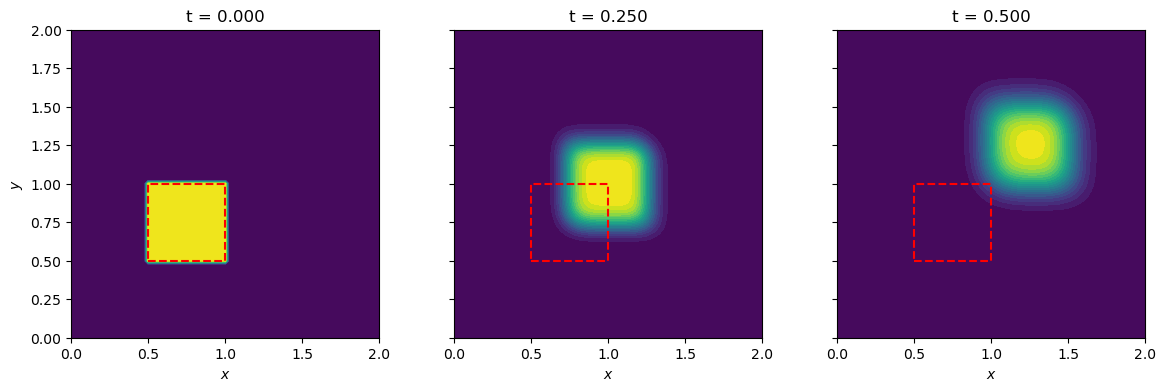

In [37]:
n_show = [0, 50, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_lin[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

### Diffusion + Advection: 
The hat travels along the diagonal, as it must, and loses its corners on the way.
That smearing is due to numerical diffusion, now acting in two directions.

### 4. The stability limit:

The analysis gives $C_x + C_y \le 1$. Let's march a few steps at several
values and look at the largest value in the field.

In [38]:
# Courant numbers
C_x = C_y = 0.6

dt = C_x*dx/c_x

# Time levels

nt = 101

t = np.arange(0., nt*dt, dt)

print(C_x, C_y)

0.6 0.6


In [39]:
u_lin = march_linear(ics, C_x, C_y, nt)

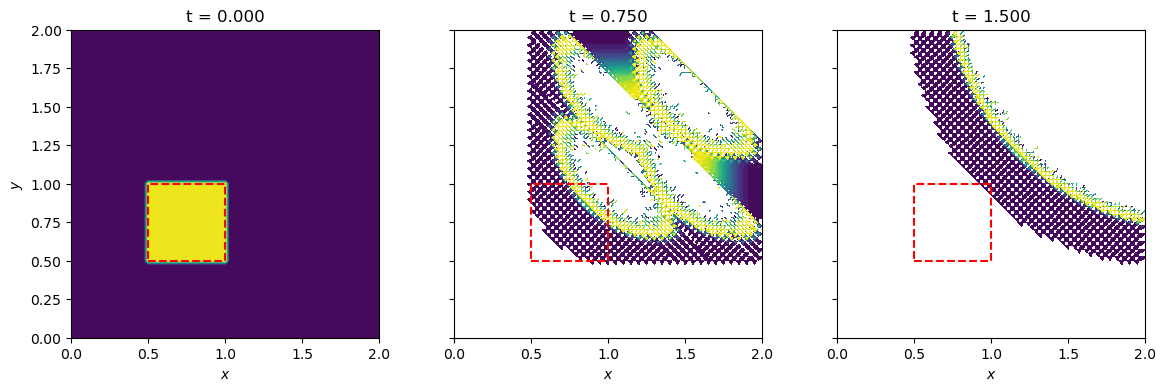

In [40]:
n_show = [0, 50, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_lin[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

The two Courant numbers add. Each one on its own is well below the
one-dimensional limit of 1, and the march still fails once their sum passes
it.

# Part II. Nonlinear advection

Now the velocity is the solution itself, and it has two components:

$$\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x}
+ v\frac{\partial u}{\partial y} = 0, \qquad
\frac{\partial v}{\partial t} + u\frac{\partial v}{\partial x}
+ v\frac{\partial v}{\partial y} = 0 .$$

We march the pair together, using the local velocity in place of $c_x$ and
$c_y$.

In [50]:
def march_nonlinear(ics_u, ics_v, dt_num, n_levels):

    u_mat = np.zeros((ics_u.shape[0], ics_u.shape[1], n_levels))
    v_mat = np.zeros_like(u_mat)

    u_mat[:, :, 0] = ics_u
    v_mat[:, :, 0] = ics_v

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, :, n-1]
        v_old = v_mat[:, :, n-1]

        u_new = u_old.copy()
        v_new = v_old.copy()

        u_new[1:, 1:] = (u_old[1:, 1:] - u_old[1:, 1:]*dt_num/dx*(u_old[1:, 1:] - u_old[:-1, 1:]) - v_old[1:, 1:]*dt_num/dy*(u_old[1:, 1:] - u_old[1:, :-1]))

        v_new[1:, 1:] = (v_old[1:, 1:] - u_old[1:, 1:]*dt_num/dx*(v_old[1:, 1:] - v_old[:-1, 1:]) - v_old[1:, 1:]*dt_num/dy*(v_old[1:, 1:] - v_old[1:, :-1]))

        for a in (u_new, v_new):
            a[0, :] = a[-1, :] = 1.
            a[:, 0] = a[:, -1] = 1.

        u_mat[:, :, n] = u_new
        v_mat[:, :, n] = v_new

    return u_mat, v_mat

In [52]:
# The largest speed is 2, so the time step has to respect it
C_x = 0.2

dt_nl = C_x*dx/2.

nt_nl = 81

t_nl = np.arange(0., nt_nl*dt_nl, dt_nl)

u_nl, v_nl = march_nonlinear(ics, ics, dt_nl, nt_nl)

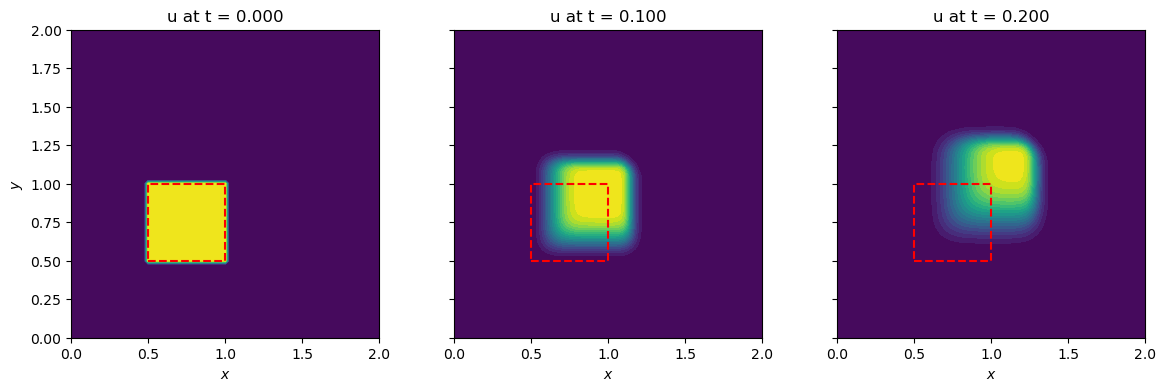

In [53]:
n_show = [0, 40, nt_nl - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_nl[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"u at t = {t_nl[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

The high part of the hat travels faster than the low part, so the front face steepens and the back face stretches.

### Summary of results

- Part I:

The hat is carried along the diagonal and its corners are rounded off.

The two Courant numbers add, and the march fails as soon as $C_x + C_y$ passes 1.

- Part II:

With the velocity equal to the solution the front face steepens and the back face stretches.

We get a shock.